In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
uber_df=pd.read_csv(r'C:\Users\ELCOT\Downloads\uberdrive.csv')

In [3]:
uber_df.head()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
0,01-01-2016 21:11,01-01-2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain
1,01-02-2016 01:25,01-02-2016 01:37,Business,Fort Pierce,Fort Pierce,5.0,NaN
2,01-02-2016 20:25,01-02-2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies
3,01-05-2016 17:31,01-05-2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting
4,01-06-2016 14:42,01-06-2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit


In [4]:
uber_df.tail()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site
1154,12/31/2016 22:08,12/31/2016 23:51,Business,Gampaha,Ilukwatta,48.2,Temporary Site
1155,Totals,NaN,NaN,NaN,NaN,12204.7,NaN


In [5]:
uber_df.drop(uber_df.index[-1],inplace=True)

In [6]:
uber_df.tail()

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
1150,12/31/2016 1:07,12/31/2016 1:14,Business,Kar?chi,Kar?chi,0.7,Meeting
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site
1154,12/31/2016 22:08,12/31/2016 23:51,Business,Gampaha,Ilukwatta,48.2,Temporary Site


In [7]:
uber_df.shape

(1155, 7)

In [8]:
uber_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1155 entries, 0 to 1154
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   START_DATE*  1155 non-null   str    
 1   END_DATE*    1155 non-null   str    
 2   CATEGORY*    1155 non-null   str    
 3   START*       1155 non-null   str    
 4   STOP*        1155 non-null   str    
 5   MILES*       1155 non-null   float64
 6   PURPOSE*     653 non-null    str    
dtypes: float64(1), str(6)
memory usage: 137.2 KB


In [9]:
uber_df.size

8085

In [10]:
uber_df.columns

Index(['START_DATE*', 'END_DATE*', 'CATEGORY*', 'START*', 'STOP*', 'MILES*',
       'PURPOSE*'],
      dtype='str')

In [11]:
uber_df.dtypes

START_DATE*        str
END_DATE*          str
CATEGORY*          str
START*             str
STOP*              str
MILES*         float64
PURPOSE*           str
dtype: object

In [12]:
import warnings
warnings.filterwarnings('ignore')

In [13]:
## Data Preprocessing
uber_df.isnull().sum()

START_DATE*      0
END_DATE*        0
CATEGORY*        0
START*           0
STOP*            0
MILES*           0
PURPOSE*       502
dtype: int64

In [14]:
 uber_df['PURPOSE*'].fillna('NOT',inplace=True)

0        Meal/Entertain
1                   NOT
2       Errand/Supplies
3               Meeting
4        Customer Visit
             ...       
1150            Meeting
1151     Temporary Site
1152            Meeting
1153     Temporary Site
1154     Temporary Site
Name: PURPOSE*, Length: 1155, dtype: str

In [15]:
### check for duplicates

uber_df[uber_df.duplicated()]

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
492,6/28/2016 23:34,6/28/2016 23:59,Business,Durham,Cary,9.9,Meeting


In [16]:
uber_df.drop_duplicates(inplace = True)

In [17]:
uber_df[uber_df.duplicated()]

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*


In [18]:
uber_df.describe()

,MILES*
count,1154.000000
mean,10.567418
std,21.588452
min,0.500000
25%,2.900000
50%,6.000000
75%,10.400000
max,310.300000


In [39]:
from datetime import datetime

uber_df['date']=pd.DatetimeIndex(uber_df['START_DATE*']).date
uber_df['Time']=pd.DatetimeIndex(uber_df['START_DATE*']).hour
uber_df['day']=pd.DatetimeIndex(uber_df['START_DATE*']).day_name()
uber_df['month']=pd.DatetimeIndex(uber_df['START_DATE*']).month_name()
uber_df['day_night'] = pd.cut(uber_df['Time'], bins=[0,10,15,19,24],
                         labels=['Morning','Afternoon','Evening','Night'])

In [20]:
uber_df['day_night'].value_counts()

day_night
Afternoon    430
Evening      345
Morning      182
Night        178
Name: count, dtype: int64

In [21]:
uber_df['month'].value_counts()

month
December     146
August       133
November     122
February     115
March        113
July         112
June         107
October      106
January       61
April         54
May           49
September     36
Name: count, dtype: int64

In [22]:
uber_df['day'].value_counts()

day
Friday       206
Tuesday      175
Monday       174
Thursday     154
Saturday     150
Sunday       148
Wednesday    147
Name: count, dtype: int64

In [23]:
uber_df['Time'].value_counts()

Time
15    98
17    95
13    94
18    94
14    89
16    88
12    77
11    72
20    71
19    68
10    65
21    51
9     51
8     35
22    31
23    25
0     19
7     13
1      5
5      4
6      4
3      3
2      2
Name: count, dtype: int64

In [24]:
uber_df['date'].value_counts()

date
2016-12-29    13
2016-02-21    11
2016-06-27    11
2016-12-19    11
2016-02-19    10
              ..
2016-10-12     1
2016-10-15     1
2016-10-21     1
2016-11-17     1
2016-12-15     1
Name: count, Length: 294, dtype: int64

In [25]:
uber_df['PURPOSE*'].value_counts()

PURPOSE*
Meeting            186
Meal/Entertain     160
Errand/Supplies    128
Customer Visit     101
Temporary Site      50
Between Offices     18
Moving               4
Airport/Travel       3
Charity ($)          1
Commute              1
Name: count, dtype: int64

In [26]:
uber_df.groupby('START*')['MILES*'].mean()

START*
Agnew                2.775000
Almond              15.200000
Apex                 5.341176
Arabi               17.000000
Arlington            4.900000
                      ...    
West University      2.200000
Weston               4.000000
Westpark Place       2.182353
Whitebridge          4.020588
Winston Salem      133.600000
Name: MILES*, Length: 177, dtype: float64

## Data Visualization

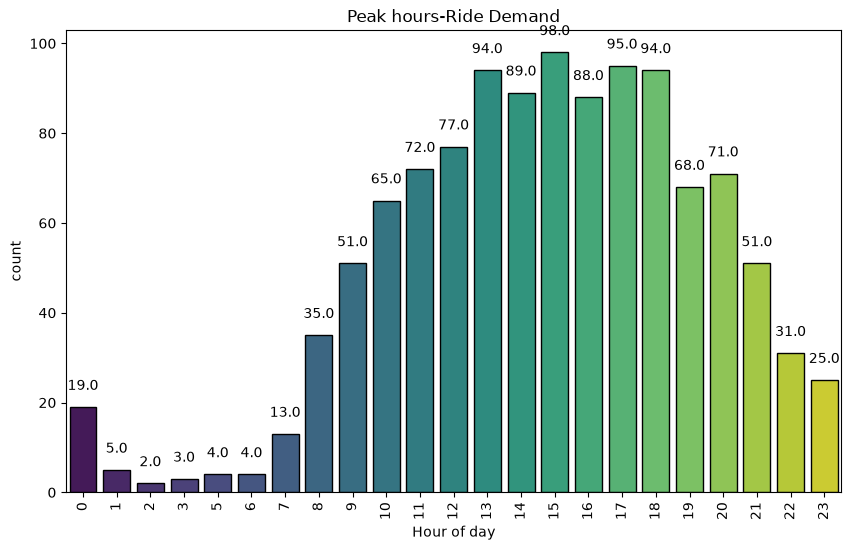

In [27]:
##1. Peak hours

plt.figure(figsize=(10,6))
ax=sns.countplot(x=uber_df['Time'],palette='viridis',edgecolor='black')
plt.xticks(rotation=90)
for p in ax.patches:
    height=p.get_height()
    if height>0:
        ax.annotate (
            f'{p.get_height():.1f}',
            (p.get_x()+p.get_width()/2.,p.get_height()),
            ha='center',va='bottom',
            xytext=(0,10),
            textcoords='offset points',
        )
plt.title('Peak hours-Ride Demand')
plt.xlabel('Hour of day')
plt.ylabel('count')
plt.show()

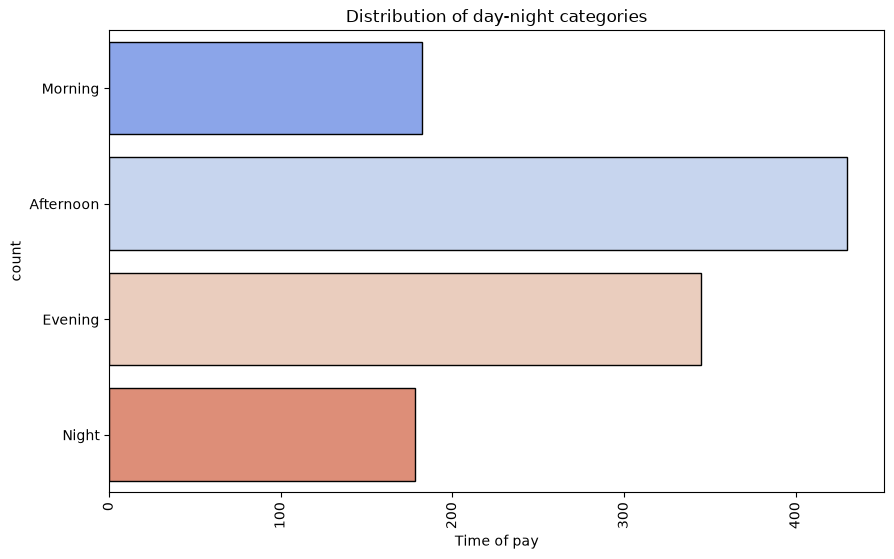

In [28]:
## 2.Distribution of day-night categories

plt.figure(figsize=(10,6))
sns.countplot(uber_df['day_night'],palette='coolwarm',edgecolor='black')
plt.xticks(rotation=90)
plt.title('Distribution of day-night categories')
plt.xlabel('Time of pay')
plt.ylabel('count')
plt.show()

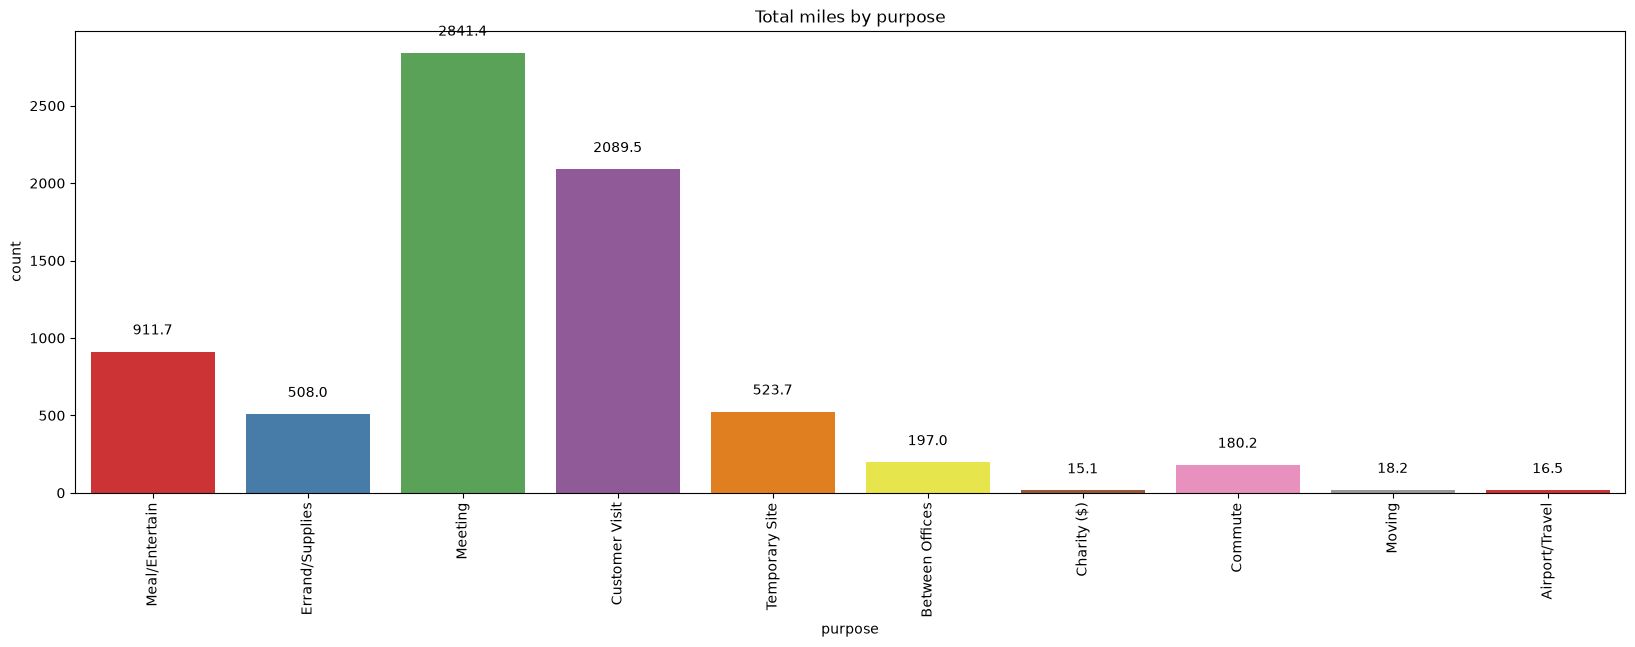

In [29]:
## 3.Total miles by purpose

plt.figure(figsize=(20,6))
ax=sns.barplot(data=uber_df,x='PURPOSE*',y='MILES*',estimator=sum,ci=None,palette='Set1')
plt.xticks(rotation=90)
for p in ax.patches:
    height=p.get_height()
    if height>0:
        ax.annotate (
            f'{p.get_height():.1f}',
            (p.get_x()+p.get_width()/2.,p.get_height()),
            ha='center',va='bottom',
            xytext=(0,10),
            textcoords='offset points',
        )
plt.title('Total miles by purpose')
plt.xlabel('purpose')
plt.ylabel('count')
plt.show()

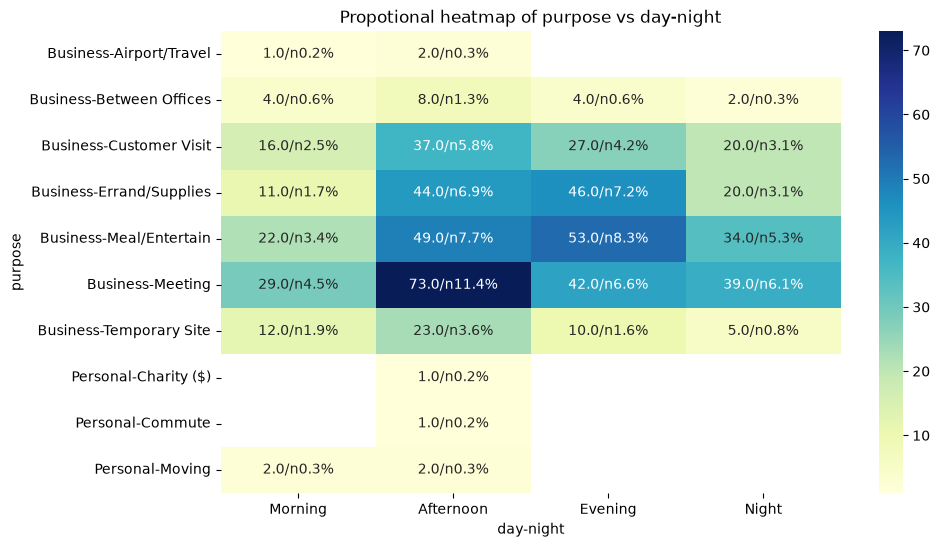

In [30]:
### 4.heatmap

plt.figure(figsize=(10,6))
heatmap_data=uber_df.groupby(['CATEGORY*','PURPOSE*','day_night']).size().unstack()
total=heatmap_data.sum().sum()
sns.heatmap(heatmap_data,annot=heatmap_data.map(lambda x:f'{x}/n{x/total:.1%}'),cmap='YlGnBu',fmt='s')
plt.title('Propotional heatmap of purpose vs day-night')
plt.xlabel('day-night')
plt.ylabel('purpose')
plt.show()

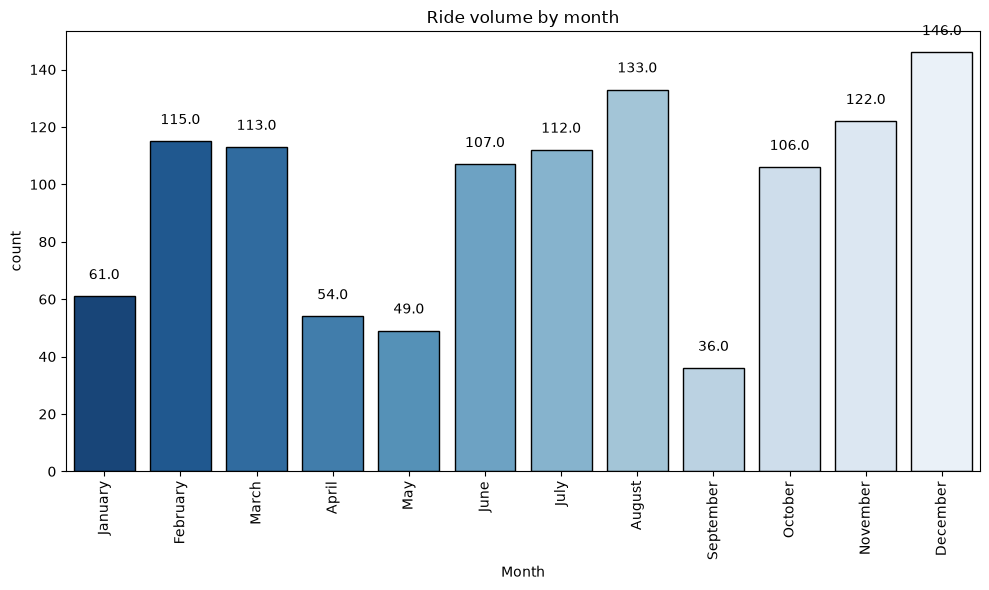

In [31]:
## 5.Monthly ride trends(Time-Series)

plt.figure(figsize=(10,6))
monthly_order=['January','February','March','April','May','June','July','August','September','October','November','December']
ax=sns.countplot(x=uber_df['month'],
              order=[m for m in monthly_order if m in uber_df['month'].unique()],
              palette='Blues_r',edgecolor='black')
plt.xticks(rotation=90)
for p in ax.patches:
    height=p.get_height()
    if height>0:
        ax.annotate (
            f'{p.get_height():.1f}',
            (p.get_x()+p.get_width()/2.,p.get_height()),
            ha='center',va='bottom',
            xytext=(0,10),
            textcoords='offset points',
        )
plt.title('Ride volume by month')
plt.xlabel('Month')
plt.ylabel('count')
plt.tight_layout()
plt.show()

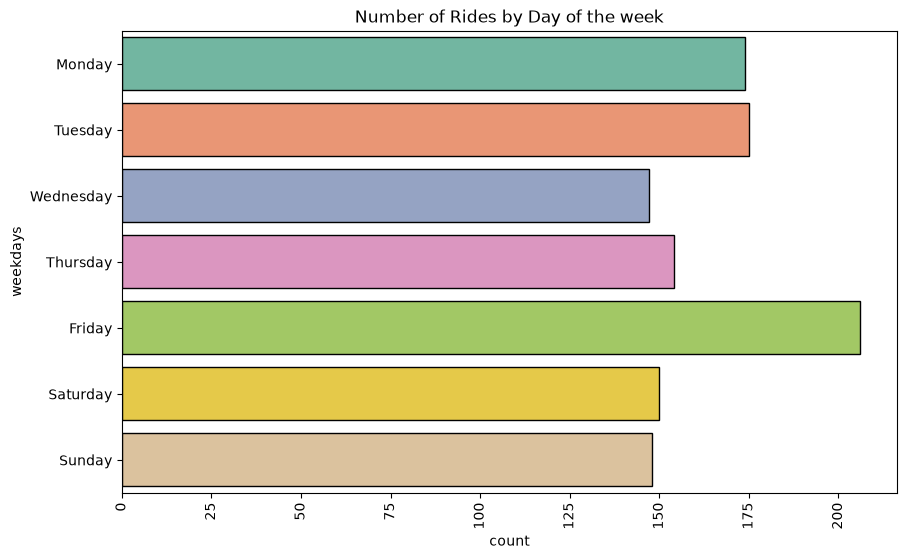

In [32]:
## 6.More rides on weekdays or weekends

plt.figure(figsize=(10,6))
sns.countplot(data=uber_df['day'],order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'],palette='Set2',edgecolor='black')
plt.xticks(rotation = 90)
plt.title('Number of Rides by Day of the week')
plt.ylabel('weekdays')
plt.xlabel('count')
plt.show()

#  Predictive Model - Ride Demand Forecasting (MILES prediction)

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error,mean_absolute_error

In [51]:
# Ride Demand Forecasting (MILES prediction)
df_model = uber_df[['Time','month','day','CATEGORY*']].copy()
df_model = pd.get_dummies(df_model, columns=['day','month','CATEGORY*'],drop_first=True,dtype=int)
x = df_model
y = uber_df['MILES*']

data=pd.concat([x,y], axis=1).dropna()
x = data.drop(columns=['MILES*'])
y = data['MILES*']
print("Data:",x.columns.tolist())


Data: ['Time', 'day_Monday', 'day_Saturday', 'day_Sunday', 'day_Thursday', 'day_Tuesday', 'day_Wednesday', 'month_August', 'month_December', 'month_February', 'month_January', 'month_July', 'month_June', 'month_March', 'month_May', 'month_November', 'month_October', 'month_September', 'CATEGORY*_Personal']


In [52]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)
model = RandomForestRegressor(n_estimators=50,random_state=42)
model.fit(x_train, y_train)
pred = model.predict(x_test)
mae = mean_absolute_error(y_test,pred)
rmse = np.sqrt(mean_squared_error(y_test,pred))
print(f"Demand Forecast MAE: {mae:.2f} miles")
print(f"Demand Forecast RMSE: {rmse:.2f} miles")

Demand Forecast MAE: 12.28 miles
Demand Forecast RMSE: 29.99 miles
